# Planejamento do Projeto — Planejamento da Cadeia de Suprimentos

## Objetivo do Projeto

Analisar e otimizar a cadeia de suprimentos de uma empresa de distribuição industrial, identificando ineficiências operacionais e propondo estratégias baseadas em dados para reduzir rupturas de estoque, melhorar o nível de serviço dos fornecedores e diminuir custos logísticos.

O projeto cobre o ciclo completo de um projeto de Ciência de Dados aplicado a Supply Chain: da exploração dos dados até a construção de modelos preditivos e geração de recomendações acionáveis para o negócio.

---

## Contexto de Negócio

A empresa distribui materiais industriais (ferramentas, EPIs, fixadores, materiais elétricos e de manutenção) para clientes em todo o Brasil. Ela trabalha com fornecedores nacionais e internacionais, com prazos de entrega que variam de 4 a 42 dias.

**Principais dores identificadas:**
- Rupturas de estoque em produtos de alto giro durante períodos de pico
- Atrasos frequentes de fornecedores internacionais que comprometem o abastecimento
- Custo logístico elevado sem visibilidade clara dos principais drivers
- Ausência de previsão de demanda estruturada — compras baseadas em experiência empírica


# Etapa 1 — Análise Exploratória de Dados (EDA)

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Objetivo:** Entender a base de dados, identificar padrões operacionais e levantar hipóteses de negócio que guiarão as etapas seguintes do projeto.

---

## 1. Importação de Bibliotecas e Carregamento dos Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

In [2]:
# Carregar base principal e tabelas de referência
df = pd.read_csv('data/base_cadeia_suprimentos.csv')
ref_produtos    = pd.read_csv('data/ref_produtos.csv')
ref_fornecedores = pd.read_csv('data/ref_fornecedores.csv')
ref_regioes     = pd.read_csv('data/ref_regioes.csv')

# Converter datas
df['data_pedido']          = pd.to_datetime(df['data_pedido'])
df['data_entrega_prevista'] = pd.to_datetime(df['data_entrega_prevista'])
df['data_entrega_real']    = pd.to_datetime(df['data_entrega_real'])

print(f'Base principal: {df.shape[0]:,} registros | {df.shape[1]} colunas')
df.head(3)

Base principal: 49,890 registros | 31 colunas


,id_pedido,data_pedido,ano,mes,trimestre,id_produto,produto,categoria,giro_produto,id_fornecedor,...,status_entrega,estoque_disponivel,estoque_minimo,estoque_maximo,ruptura_estoque,custo_frete,custo_armazenagem,prazo_pagamento_dias,regiao_destino,estado_destino
0,PED034492,2022-01-01,2022,1,T1,P013,Tinta Epóxi 18L,Materiais,baixo,F009,...,Entregue com Atraso,159,30,300,False,530.55,37.14,30,Sudeste,Bahia
1,PED024134,2022-01-01,2022,1,T1,P008,Óculos de Segurança,EPI,alto,F004,...,Entregue no Prazo,1296,300,3000,False,112.82,78.72,30,Nordeste,São Paulo
2,PED022326,2022-01-01,2022,1,T1,P008,Óculos de Segurança,EPI,alto,F004,...,Entregue no Prazo,993,300,3000,False,116.95,64.71,45,Sudeste,Minas Gerais


In [ ]:

df['ruptura_real'] = (df['quantidade_pedida'] > df['estoque_disponivel']).astype(int)

print(df['ruptura_real'].value_counts())
print(f"Percentage of ruptures: {df['ruptura_real'].mean() * 100:.2f}%")

ruptura_real
0    48439
1     1451
Name: count, dtype: int64
Percentage of ruptures: 2.91%


## 2. Visão Geral da Base

In [4]:
print('=== TIPOS E NULOS ===')
info = pd.DataFrame({
    'dtype':  df.dtypes,
    'nulos':  df.isnull().sum(),
    '% nulo': (df.isnull().mean() * 100).round(2)
})
display(info)

print('\n=== ESTATÍSTICAS DESCRITIVAS (numéricas) ===')
display(df.describe().round(2))

=== TIPOS E NULOS ===


,dtype,nulos,% nulo
id_pedido,object,0,0.0
data_pedido,datetime64[ns],0,0.0
ano,int64,0,0.0
mes,int64,0,0.0
trimestre,object,0,0.0
id_produto,object,0,0.0
produto,object,0,0.0
categoria,object,0,0.0
giro_produto,object,0,0.0
id_fornecedor,object,0,0.0



=== ESTATÍSTICAS DESCRITIVAS (numéricas) ===


,data_pedido,ano,mes,confiabilidade_forn,quantidade_pedida,preco_unitario,valor_total_pedido,prazo_entrega_acordado_dias,data_entrega_prevista,data_entrega_real,atraso_dias,estoque_disponivel,estoque_minimo,estoque_maximo,custo_frete,custo_armazenagem,prazo_pagamento_dias,ruptura_real
count,49890,49890.00,49890.00,49890.00,49890.00,49890.00,49890.00,49890.00,49890,49890,49890.00,49890.00,49890.00,49890.00,49890.00,49890.00,49890.00,49890.00
mean,2023-07-04 03:31:54.948887808,2023.01,6.51,0.90,249.93,21.87,3351.43,11.29,2023-07-15 10:33:36.692723968,2023-07-15 12:31:01.695730432,0.38,1042.37,346.76,3235.34,207.85,84.05,41.91,0.03
min,2022-01-01 00:00:00,2022.00,1.00,0.75,1.00,1.10,1.10,3.00,2022-01-04 00:00:00,2022-01-03 00:00:00,0.00,40.00,20.00,150.00,80.75,0.01,30.00,0.00
25%,2022-10-01 00:00:00,2022.00,4.00,0.88,98.00,3.45,806.27,5.00,2022-10-11 00:00:00,2022-10-11 06:00:00,0.00,517.00,200.00,2000.00,118.52,17.91,30.00,0.00
50%,2023-07-06 00:00:00,2023.00,7.00,0.90,230.00,12.77,1871.92,6.00,2023-07-17 00:00:00,2023-07-17 00:00:00,0.00,891.00,300.00,3000.00,140.87,44.62,45.00,0.00
75%,2024-04-06 00:00:00,2024.00,10.00,0.95,378.00,26.62,4626.37,10.00,2024-04-17 00:00:00,2024-04-17 00:00:00,0.00,1444.00,500.00,5000.00,202.18,110.63,45.00,0.00
max,2024-12-31 00:00:00,2024.00,12.00,0.97,1056.00,582.32,30560.45,50.00,2025-02-16 00:00:00,2025-02-21 00:00:00,30.00,3996.00,800.00,6000.00,844.80,1101.11,60.00,1.00
std,NaN,0.82,3.45,0.05,174.85,47.76,3768.11,10.92,NaN,NaN,2.01,654.73,216.78,1765.01,153.51,104.19,11.20,0.17


In [5]:
# Período coberto
print(f"Período: {df['data_pedido'].min().date()} a {df['data_pedido'].max().date()}")
print(f"Anos:    {sorted(df['ano'].unique())}")
print(f"Produtos únicos:    {df['id_produto'].nunique()}")
print(f"Fornecedores únicos: {df['id_fornecedor'].nunique()}")
print(f"Estados de destino:  {df['estado_destino'].nunique()}")
print(f"Categorias:  {df['categoria'].nunique()}")

Período: 2022-01-01 a 2024-12-31
Anos:    [np.int64(2022), np.int64(2023), np.int64(2024)]
Produtos únicos:    20
Fornecedores únicos: 10
Estados de destino:  13
Categorias:  6


## Metadados do Dataset

| Atributo              | Valor                        |
|-----------------------|------------------------------|
| **Período coberto**   | 01/01/2022 a 31/12/2024      |
| **Anos disponíveis**  | 2022, 2023, 2024             |
| **Produtos únicos**   | 20                           |
| **Fornecedores únicos** | 10                         |
| **Estados de destino** | 13                          |
| **Categorias**        | 6                            |

## 3. Distribuição dos Pedidos

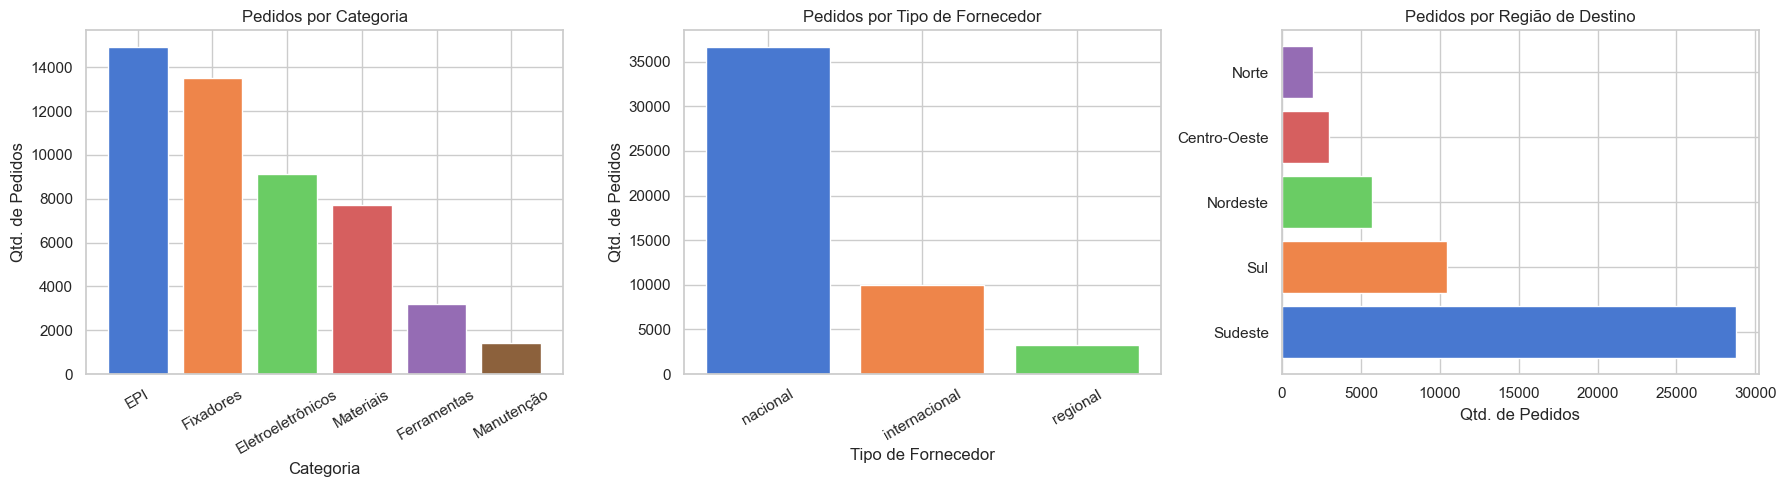

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Por categoria
cat_counts = df['categoria'].value_counts()
axes[0].bar(cat_counts.index, cat_counts.values, color=sns.color_palette('muted', len(cat_counts)))
axes[0].set_title('Pedidos por Categoria')
axes[0].set_xlabel('Categoria')
axes[0].set_ylabel('Qtd. de Pedidos')
axes[0].tick_params(axis='x', rotation=30)

# Por tipo de fornecedor
tipo_counts = df['tipo_fornecedor'].value_counts()
axes[1].bar(tipo_counts.index, tipo_counts.values, color=sns.color_palette('muted', len(tipo_counts)))
axes[1].set_title('Pedidos por Tipo de Fornecedor')
axes[1].set_xlabel('Tipo de Fornecedor')
axes[1].set_ylabel('Qtd. de Pedidos')
axes[1].tick_params(axis='x', rotation=30)

# Por região de destino
reg_counts = df['regiao_destino'].value_counts()
axes[2].barh(reg_counts.index, reg_counts.values, color=sns.color_palette('muted', len(reg_counts)))
axes[2].set_title('Pedidos por Região de Destino')
axes[2].set_xlabel('Qtd. de Pedidos')

plt.tight_layout()
plt.show()

#### Pedidos por categoria:
→ Curva ABC clara: EPI e Fixadores devem ter gestão prioritária de estoque e fornecedores dedicados.

#### Pedidos por tipo de Fornecedor:
→ Concentração em fornecedores nacionais reduz lead time, mas aumenta vulnerabilidade a choques locais. Oportunidade de diversificação com fornecedores regionais, ainda subutilizados.

#### Pedidos por Região de Destino:
→ Sudeste e Sul juntos representam ~80% do volume. Estrutura logística e estoques devem ser dimensionados com foco nessas regiões, sem negligenciar o Nordeste como mercado emergente.

### Conclusão: 
A operação apresenta três padrões de concentração: nos produtos (EPI e Fixadores), nos fornecedores (nacionais) e na distribuição geográfica (Sudeste). Essa estrutura é eficiente no curto prazo, mas eleva o risco operacional. A prioridade estratégica deve ser diversificar a base de fornecedores regionais e avaliar se a baixa penetração em Norte e Centro-Oeste é uma lacuna de mercado ou uma limitação logística.

## 4. Análise Temporal — Sazonalidade da Demanda

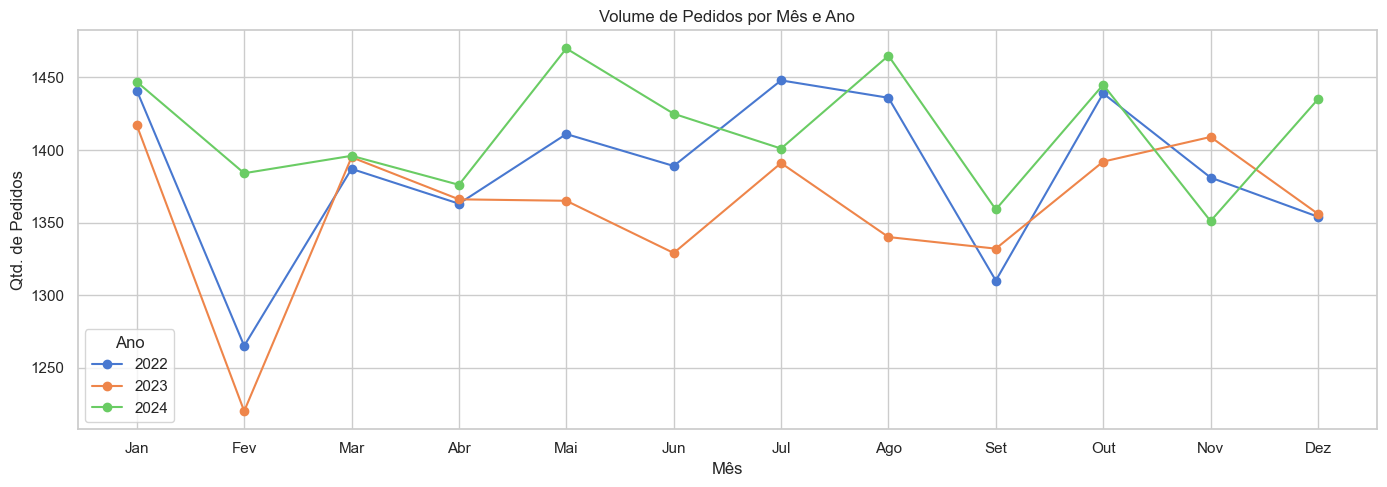

In [7]:
# Volume de pedidos por mês/ano
pedidos_mes = df.groupby(['ano', 'mes']).size().reset_index(name='qtd_pedidos')
pedidos_mes['periodo'] = pd.to_datetime(pedidos_mes[['ano','mes']].assign(day=1).rename(columns={'ano': 'year', 'mes': 'month'}))

fig, ax = plt.subplots(figsize=(14, 5))
for ano, grupo in pedidos_mes.groupby('ano'):
    ax.plot(grupo['mes'], grupo['qtd_pedidos'], marker='o', label=str(ano))
ax.set_title('Volume de Pedidos por Mês e Ano')
ax.set_xlabel('Mês')
ax.set_ylabel('Qtd. de Pedidos')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez'])
ax.legend(title='Ano')
plt.tight_layout()
plt.show()

## Análise: Volume de Pedidos por Mês e Ano

### Visão Geral
O gráfico apresenta a quantidade de pedidos mensais ao longo de três anos (2022, 2023 e 2024),
permitindo comparação sazonal e tendência interanual.

---

### Observações por Ano

**2022 (azul)**
- Inicia forte em Janeiro (~1.440) e despenca em Fevereiro (~1.265) — maior queda absoluta do ano.
- Recuperação gradual até Julho (~1.450), o pico do ano.
- Nova queda acentuada em Setembro (~1.310), seguida de recuperação em Outubro (~1.440).
- Encerra o ano em queda suave (~1.380).

**2023 (laranja)**
- Ano de menor volume geral — consistentemente abaixo de 2022 e 2024.
- Fevereiro registra o ponto mais baixo de toda a série (~1.225).
- Leve crescimento no segundo semestre, mas sem ultrapassar os patamares dos outros anos.
- Dezembro termina em ~1.355, o menor fechamento de ano entre os três.

**2024 (verde)**
- Ano de maior volume — domina a maioria dos meses.
- Pico máximo de toda a série em Maio (~1.470).
- Segundo pico expressivo em Agosto (~1.465).
- Queda em Setembro (~1.360) e Novembro (~1.350), mas recupera em Dezembro (~1.435).

---

### Padrões Sazonais Identificados

| Período      | Comportamento recorrente                          |
|--------------|---------------------------------------------------|
| Janeiro      | Início forte nos três anos (~1.415–1.450)         |
| Fevereiro    | Queda acentuada em todos os anos (vale sazonal)   |
| Mar–Mai      | Recuperação e crescimento consistente             |
| Junho        | Leve retração intermediária                       |
| Jul–Ago      | Pico do segundo semestre                          |
| Setembro     | Queda recorrente (vale do segundo semestre)       |
| Out–Dez      | Recuperação parcial, sem atingir os picos anuais  |

---

### Conclusões

- **Fevereiro e Setembro** são os meses de menor demanda de forma recorrente — indicam
  sazonalidade negativa estrutural.
- **2024 apresenta crescimento consistente** em relação aos anos anteriores, sugerindo
  expansão da demanda.
- **2023 foi o ano mais fraco**, possivelmente refletindo algum fator operacional ou de mercado.
- A amplitude entre pico e vale em 2022 (~185 pedidos) é a maior entre os três anos,
  indicando maior volatilidade naquele período.

## Demanda Total (Qtd.) por Mês e Categoria

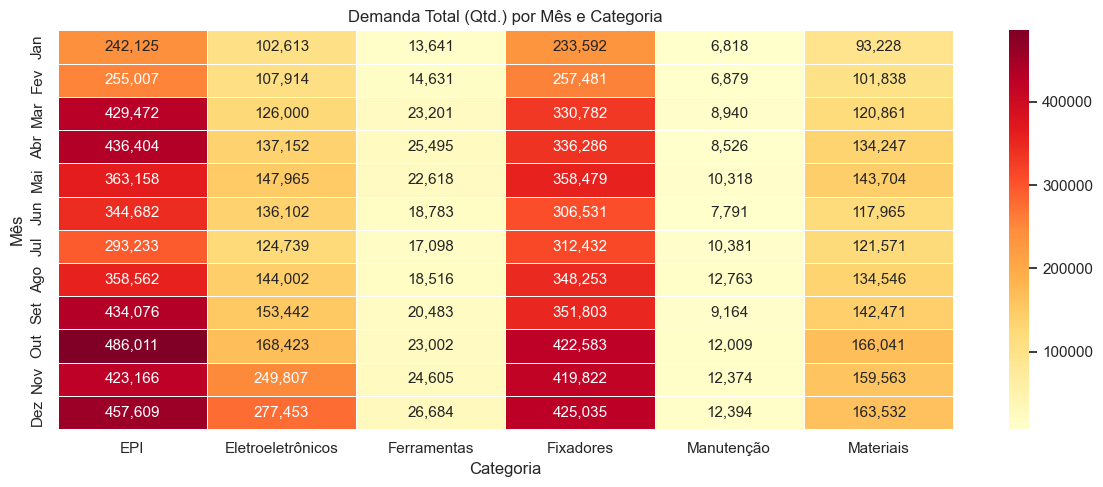

In [8]:
# Demanda por categoria ao longo dos meses (heatmap)
pivot = df.groupby(['mes', 'categoria'])['quantidade_pedida'].sum().unstack(fill_value=0)
pivot.index = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt=',', cmap='YlOrRd', linewidths=0.5)
plt.title('Demanda Total (Qtd.) por Mês e Categoria')
plt.ylabel('Mês')
plt.xlabel('Categoria')
plt.tight_layout()
plt.show()

## Análise: Demanda Total (Qtd.) por Mês e Categoria

### Visão Geral
Heatmap de demanda mensal segmentada em 6 categorias de produtos ao longo de 12 meses.
A escala de cor vai do amarelo claro (baixa demanda) ao vermelho escuro (alta demanda),
facilitando a leitura visual dos picos e vales por categoria.

---

### Ranking de Categorias por Volume Total

| Categoria        | Perfil de Volume | Observação                              |
|------------------|------------------|-----------------------------------------|
| **Fixadores**    | Muito Alto       | Domina em vermelho escuro quase todos os meses |
| **EPI**          | Muito Alto       | Segundo maior volume; forte no 2º semestre     |
| **Eletroeletrônicos** | Médio       | Crescimento expressivo em Nov/Dez              |
| **Materiais**    | Médio-Baixo      | Comportamento estável ao longo do ano          |
| **Ferramentas**  | Baixo            | Menor variação absoluta entre os meses         |
| **Manutenção**   | Muito Baixo      | Volumes consistentemente os menores da tabela  |

---

### Observações por Categoria

**EPI**
- Pico máximo em **Outubro** (486.011) — maior valor absoluto de toda a tabela.
- Queda notável em **Janeiro e Fevereiro** (~242–255k), indicando baixa sazonalidade no início do ano.
- Forte aceleração a partir de **Março** (~429k), mantendo-se elevado até Dezembro.

**Fixadores**
- Categoria de maior demanda junto com EPI.
- Pico em **Dezembro** (425.035) e **Outubro** (422.583).
- Vale em **Janeiro** (233.592) — menor mês da categoria.
- Padrão crescente ao longo do ano, com leve queda em Junho/Julho.

**Eletroeletrônicos**
- Apresenta crescimento progressivo e consistente ao longo do ano.
- Salto significativo nos últimos meses: **Novembro** (249.807) e **Dezembro** (277.453)
  — quase o dobro dos valores de Janeiro/Fevereiro (~102–107k).
- Possível influência de demanda por reposição no fim de ano.

**Materiais**
- Comportamento estável e moderado (~93k–166k).
- Crescimento suave ao longo do ano, com pico em **Outubro** (166.041).

**Ferramentas**
- Menores volumes absolutos entre as categorias de média relevância.
- Pico em **Dezembro** (26.684) e vale em **Janeiro** (13.641).
- Variação proporcional similar ao restante, mas sem grandes oscilações.

**Manutenção**
- Categoria de menor demanda em todos os meses (6.818 a 12.763).
- Crescimento gradual ao longo do ano; sem picos expressivos.

---

### Padrões Sazonais Identificados

| Período       | Comportamento                                                  |
|---------------|----------------------------------------------------------------|
| Jan–Fev       | Vale generalizado em todas as categorias                       |
| Mar–Abr       | Aceleração brusca, especialmente em EPI e Fixadores            |
| Mai–Jul       | Estabilização ou leve retração intermediária                   |
| Ago–Set       | Retomada do crescimento no segundo semestre                    |
| Out–Dez       | Pico anual na maioria das categorias — maior pressão de demanda|

---

### Conclusões

- **Outubro a Dezembro** é o trimestre crítico de demanda — concentra os maiores volumes
  em quase todas as categorias, exigindo maior capacidade de estoque e logística.
- **EPI e Fixadores** são as categorias estratégicas pelo peso no volume total.
- **Eletroeletrônicos** exige atenção especial no planejamento do 4º trimestre,
  dado o crescimento acelerado em Nov/Dez.
- **Janeiro e Fevereiro** representam o período de menor pressão operacional —
  oportunidade para reposição de estoques e manutenção preventiva.

## 5. Análise de Atrasos

In [9]:
# Status de entrega geral
status_counts = df['status_entrega'].value_counts()
pct_atraso = (df['status_entrega'] == 'Entregue com Atraso').mean() * 100
print(f'Taxa de atraso geral: {pct_atraso:.1f}%\n')
print(status_counts.to_string())

Taxa de atraso geral: 9.9%

status_entrega
Entregue no Prazo      44473
Entregue com Atraso     4942
Em Trânsito              475


### Taxa de Atraso Geral
- **9,9%** das entregas foram realizadas com atraso.

### Distribuição por Status de Entrega

| Status             | Quantidade | Participação (%) |
|--------------------|------------|------------------|
| Entregue no Prazo  | 44.473     | ~88,2%           |
| Entregue com Atraso| 4.942      | ~9,9%            |
| Em Trânsito        | 475        | ~0,9%            |
| **Total**          | **49.890** | **100%**         |

### Observações

- A grande maioria das entregas (~88%) ocorre dentro do prazo, indicando
  boa performance geral da cadeia logística.
- Aproximadamente **1 em cada 10 pedidos** chega com atraso — patamar
  relevante que merece investigação por rota, fornecedor ou categoria.
- Os **475 registros "Em Trânsito"** representam pedidos ainda em aberto
  no momento do corte dos dados; não devem ser contabilizados como atraso
  até a confirmação da entrega.

## Atrasos por Tipo de Fornecedor e Distribuição

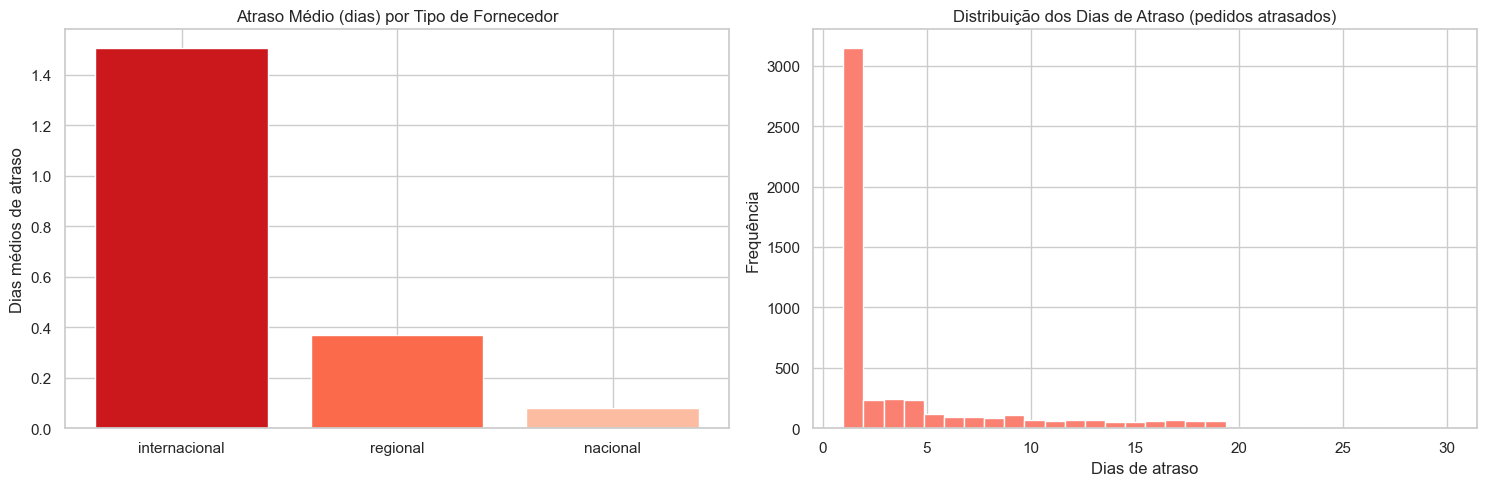

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Atraso médio por tipo de fornecedor
atraso_tipo = df.groupby('tipo_fornecedor')['atraso_dias'].mean().sort_values(ascending=False)
axes[0].bar(atraso_tipo.index, atraso_tipo.values, color=sns.color_palette('Reds_r', len(atraso_tipo)))
axes[0].set_title('Atraso Médio (dias) por Tipo de Fornecedor')
axes[0].set_ylabel('Dias médios de atraso')

# Distribuição dos dias de atraso
atrasados = df[df['atraso_dias'] > 0]['atraso_dias']
axes[1].hist(atrasados, bins=30, color='salmon', edgecolor='white')
axes[1].set_title('Distribuição dos Dias de Atraso (pedidos atrasados)')
axes[1].set_xlabel('Dias de atraso')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

## Análise de Atrasos por Tipo de Fornecedor e Distribuição

---

### Gráfico 1 — Atraso Médio (dias) por Tipo de Fornecedor

| Tipo de Fornecedor | Atraso Médio (dias) | Intensidade |
|--------------------|---------------------|-------------|
| Internacional      | ~1,5 dias           | Alta        |
| Regional           | ~0,37 dias          | Média       |
| Nacional           | ~0,10 dias          | Baixa       |

**Observações:**
- Fornecedores **internacionais** apresentam atraso médio ~4x maior que regionais
  e ~15x maior que nacionais — diferença expressiva e esperada dado o maior
  lead time de importação.
- Fornecedores **nacionais** têm desempenho de entrega notavelmente superior,
  reforçando a vantagem logística da proximidade geográfica.
- A escala de cor (vermelho escuro → claro) reforça visualmente a hierarquia de risco.

---

### Gráfico 2 — Distribuição dos Dias de Atraso (pedidos atrasados)

**Observações:**
- Distribuição fortemente **assimétrica à direita** (cauda longa).
- A grande concentração ocorre em **1 a 2 dias de atraso** (~3.100 ocorrências),
  indicando que a maioria dos atrasos é de curta duração.
- A frequência cai drasticamente a partir de **3 dias** e se torna residual
  após **10 dias**.
- Existem ocorrências esparsas de até **~28–30 dias** de atraso,
  caracterizando casos extremos (outliers) que merecem investigação pontual.

---

### Conclusões Combinadas

- O problema de atraso é majoritariamente **superficial em duração** —
  a maioria dos pedidos atrasa apenas 1 ou 2 dias.
- O **fornecedor internacional** é o principal vetor de risco de atraso;
  ações de mitigação (buffer de estoque, antecipação de pedidos) devem
  ser priorizadas nesse segmento.
- Os atrasos longos (>10 dias), embora raros, podem representar rupturas
  críticas — recomenda-se análise de causa raiz nesses casos isolados.

## Taxa de atraso por Fornecedores

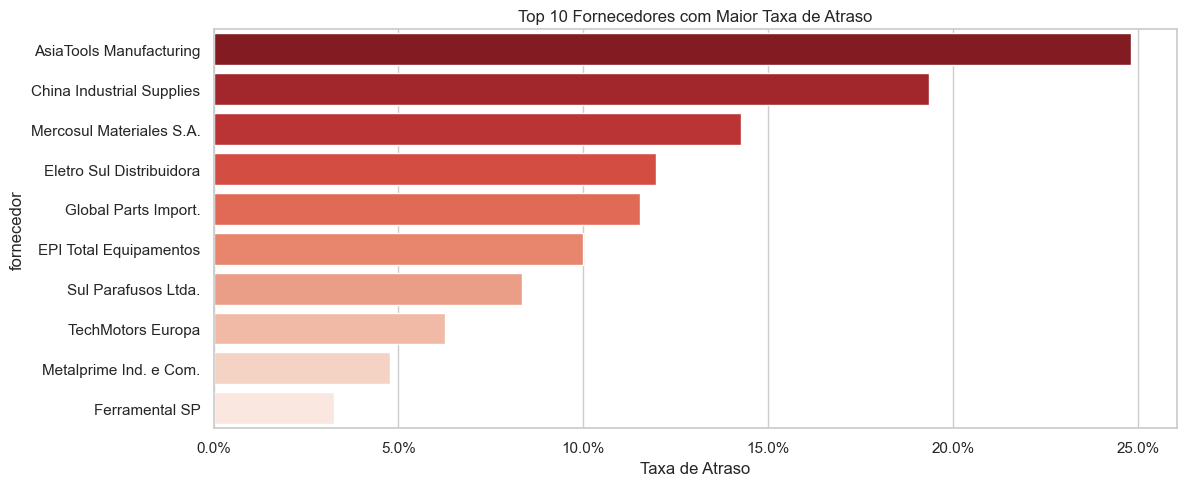

In [11]:
# Top 10 fornecedores com maior taxa de atraso
taxa_atraso_forn = (
    df.groupby('fornecedor')
    .apply(lambda x: (x['status_entrega'] == 'Entregue com Atraso').mean())
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
taxa_atraso_forn.columns = ['fornecedor', 'taxa_atraso']

plt.figure(figsize=(12, 5))
sns.barplot(data=taxa_atraso_forn, x='taxa_atraso', y='fornecedor', palette='Reds_r')
plt.title('Top 10 Fornecedores com Maior Taxa de Atraso')
plt.xlabel('Taxa de Atraso')
plt.gca().xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## Top 10 Fornecedores com Maior Taxa de Atraso

---

### Ranking Completo

| # | Fornecedor                  | Taxa de Atraso (aprox.) | Tipo Inferido  |
|---|-----------------------------|-------------------------|----------------|
| 1 | AsiaTools Manufacturing     | ~25%                    | Internacional  |
| 2 | China Industrial Supplies   | ~19%                    | Internacional  |
| 3 | Mercosul Materiales S.A.    | ~14%                    | Regional       |
| 4 | Eletro Sul Distribuidora    | ~12,5%                  | Nacional       |
| 5 | Global Parts Import.        | ~12%                    | Internacional  |
| 6 | EPI Total Equipamentos      | ~10%                    | Nacional       |
| 7 | Sul Parafusos Ltda.         | ~8,5%                   | Nacional       |
| 8 | TechMotors Europa           | ~6,5%                   | Internacional  |
| 9 | Metalprime Ind. e Com.      | ~4,5%                   | Nacional       |
| 10| Ferramental SP              | ~3,5%                   | Nacional       |

---

### Observações

**Fornecedores críticos (>15% de atraso):**
- **AsiaTools Manufacturing** lidera com folga (~25%) — 1 em cada 4 pedidos chega atrasado.
- **China Industrial Supplies** (~19%) confirma o padrão de alto risco dos fornecedores asiáticos.
- Ambos reforçam a análise anterior de que o segmento **internacional** concentra
  os maiores índices de atraso.

**Zona de atenção (10%–15%):**
- **Mercosul Materiales S.A.** (~14%) é um alerta relevante por ser regional —
  a distância não justifica plenamente essa taxa.
- **Eletro Sul Distribuidora** e **Global Parts Import.** (~12%) também demandam
  planos de melhoria contratual ou de SLA.

**Fornecedores em nível aceitável (<10%):**
- **EPI Total Equipamentos**, **Sul Parafusos**, **TechMotors Europa**,
  **Metalprime** e **Ferramental SP** operam abaixo de 10%, com
  **Ferramental SP** apresentando a melhor performance do ranking (~3,5%).

---

### Conclusões

- Os **2 primeiros fornecedores concentram o maior risco logístico** e devem
  ser priorizados em renegociações de prazo, penalidades contratuais ou
  substituição por alternativas nacionais.
- A presença de fornecedores nacionais no ranking (Eletro Sul, EPI Total, Sul Parafusos)
  indica que o atraso **não é exclusividade de importados** — há oportunidade de
  melhoria operacional interna também.
- Recomenda-se definir um **threshold de SLA** (ex: máximo 5% de atraso) e
  monitorar trimestralmente os fornecedores que ultrapassam esse limite.

## 6. Análise de Rupturas de Estoque

Taxa de ruptura geral: 2.9%


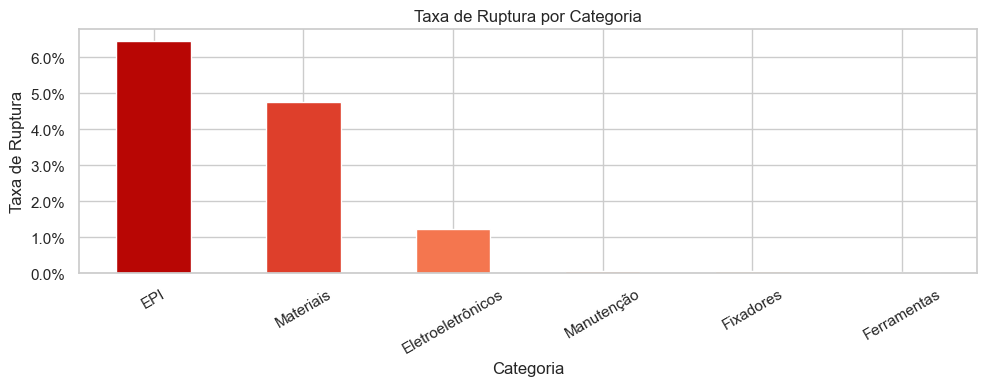

In [17]:
taxa_ruptura_geral = df['ruptura_real'].sum() / df.shape[0] * 100
print(f'Taxa de ruptura geral: {taxa_ruptura_geral:.1f}%')

# Ruptura por categoria
ruptura_cat = df.groupby('categoria')['ruptura_real'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
ruptura_cat.plot(kind='bar', color=sns.color_palette('OrRd_r', len(ruptura_cat)), edgecolor='white')
plt.title('Taxa de Ruptura por Categoria')
plt.ylabel('Taxa de Ruptura')
plt.xlabel('Categoria')
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Análise de Rupturas de Estoque

### Taxa de Ruptura Geral
- **2,9%** dos registros apresentaram ruptura real de estoque.

---

### Taxa de Ruptura por Categoria

| # | Categoria         | Taxa de Ruptura (aprox.) | Nível de Risco |
|---|-------------------|--------------------------|----------------|
| 1 | EPI               | ~6,5%                    | Alto           |
| 2 | Materiais         | ~4,8%                    | Médio-Alto     |
| 3 | Eletroeletrônicos | ~1,2%                    | Baixo          |
| 4 | Manutenção        | ~0%                      | Desprezível    |
| 5 | Fixadores         | ~0%                      | Desprezível    |
| 6 | Ferramentas       | ~0%                      | Desprezível    |

---

### Observações

**EPI — categoria crítica (~6,5%):**
- Maior taxa de ruptura da análise — mais que o dobro da média geral (2,9%).
- Dado o alto volume de demanda desta categoria (conforme análise anterior),
  a ruptura de EPI representa risco operacional e de **conformidade de segurança**
  para a operação.

**Materiais (~4,8%):**
- Segunda categoria mais afetada; também de alto volume absoluto de pedidos.
- A combinação de **alta demanda + taxa de ruptura elevada** sugere que o
  ponto de reposição (reorder point) pode estar subdimensionado.

**Eletroeletrônicos (~1,2%):**
- Ruptura baixa, mas não nula — merece monitoramento, especialmente
  considerando o crescimento de demanda em Nov/Dez identificado anteriormente.

**Manutenção, Fixadores e Ferramentas (~0%):**
- Estoque aparentemente bem dimensionado nessas categorias.
- Fixadores, apesar do maior volume de demanda, não apresenta rupturas —
  indicando boa gestão de reposição.

---

### Conclusões

- A taxa geral de **2,9%** é relativamente controlada, mas concentrada em
  apenas 2 categorias (**EPI e Materiais**), que juntas puxam a média para cima.
- **EPI deve ser prioridade imediata** de revisão de política de estoque mínimo,
  pois une alto volume de demanda com a maior taxa de ruptura.
- Recomenda-se revisar o **estoque de segurança e lead time de reposição**
  para EPI e Materiais, utilizando como referência os meses de maior demanda
  identificados (Out–Dez).

## Evolução da Taxa de Ruptura por Trimestre

Taxa de ruptura por giro do produto:
  alto    : 3.8%
  medio   : 0.6%
  baixo   : 0.1%


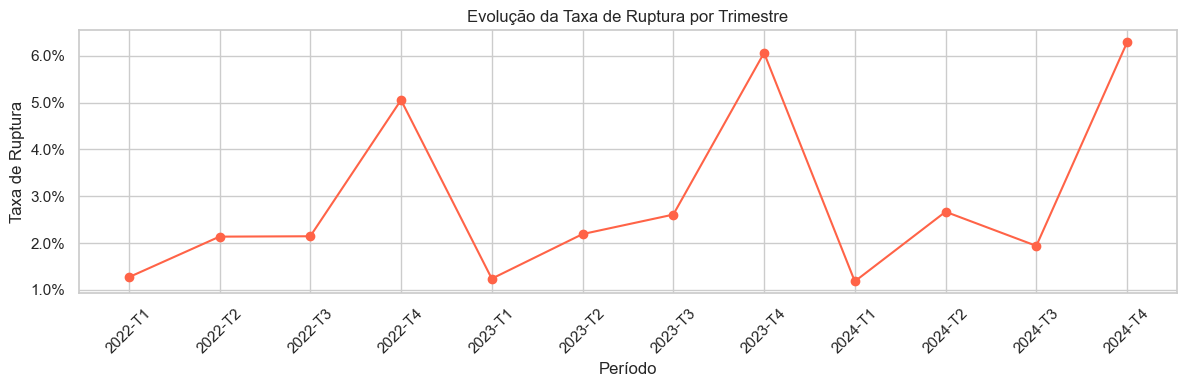

In [19]:
# Ruptura por giro do produto
ruptura_giro = df.groupby('giro_produto')['ruptura_real'].mean().sort_values(ascending=False)
print('Taxa de ruptura por giro do produto:')
for giro, taxa in ruptura_giro.items():
    print(f'  {giro:8s}: {taxa*100:.1f}%')

# Evolução das rupturas por trimestre
ruptura_trim = df.groupby(['ano', 'trimestre'])['ruptura_real'].mean().reset_index()
ruptura_trim['periodo'] = ruptura_trim['ano'].astype(str) + '-' + ruptura_trim['trimestre']

plt.figure(figsize=(12, 4))
plt.plot(ruptura_trim['periodo'], ruptura_trim['ruptura_real'], marker='o', color='tomato')
plt.title('Evolução da Taxa de Ruptura por Trimestre')
plt.ylabel('Taxa de Ruptura')
plt.xlabel('Período')
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Evolução da Taxa de Ruptura por Trimestre

### Taxa de Ruptura por Giro do Produto

| Giro do Produto | Taxa de Ruptura |
|-----------------|-----------------|
| Alto            | 3,8%            |
| Médio           | 0,6%            |
| Baixo           | 0,1%            |

> Produtos de **alto giro** concentram quase toda a ruptura — estoque insuficiente
> para acompanhar a rotatividade elevada.

---

### Evolução Trimestral

| Período  | Taxa (aprox.) | Tendência        |
|----------|---------------|------------------|
| 2022-T1  | ~1,3%         | Baixa inicial    |
| 2022-T2  | ~2,2%         | Subida           |
| 2022-T3  | ~2,2%         | Estável          |
| 2022-T4  | ~5,0%         | Pico do ano      |
| 2023-T1  | ~1,3%         | Queda abrupta    |
| 2023-T2  | ~2,2%         | Recuperação      |
| 2023-T3  | ~2,6%         | Subida leve      |
| 2023-T4  | ~6,0%         | Novo pico (maior)|
| 2024-T1  | ~1,2%         | Queda abrupta    |
| 2024-T2  | ~2,7%         | Recuperação      |
| 2024-T3  | ~2,0%         | Leve recuo       |
| 2024-T4  | ~6,3%         | Pico máximo      |

---

### Observações

**Padrão sazonal altamente recorrente:**
- O **4º trimestre (T4)** concentra os picos de ruptura em todos os anos —
  coincidindo com o período de maior demanda identificado nas análises anteriores.
- O **1º trimestre (T1)** registra consistentemente os menores índices (~1,2–1,3%),
  funcionando como período de recuperação de estoque.

**Tendência de agravamento ano a ano:**
- Os picos de T4 crescem progressivamente: **5,0% (2022) → 6,0% (2023) → 6,3% (2024)**.
- Indica que a capacidade de reposição **não está acompanhando o crescimento da demanda**.

**Oscilação estrutural (dente de serra):**
- O gráfico exibe um padrão cíclico claro de alta no T4 seguida de queda no T1,
  repetindo-se nos três anos — comportamento previsível e, portanto, planejável.

---

### Conclusões

- A ruptura de estoque é **previsível e sazonal** — o T4 é o período crítico em
  todos os anos analisados.
- A combinação com os dados de **giro alto (3,8% de ruptura)** aponta que os
  produtos mais vendidos são exatamente os mais vulneráveis à falta de estoque.
- Recomenda-se **antecipar compras e aumentar o estoque de segurança no T3**
  para absorver a pressão do T4, especialmente nas categorias EPI e Materiais.
- Se a tendência de crescimento dos picos continuar, o T4 de 2025 pode
  ultrapassar **7%** sem intervenção preventiva.

## 7. Análise de Custos Logísticos

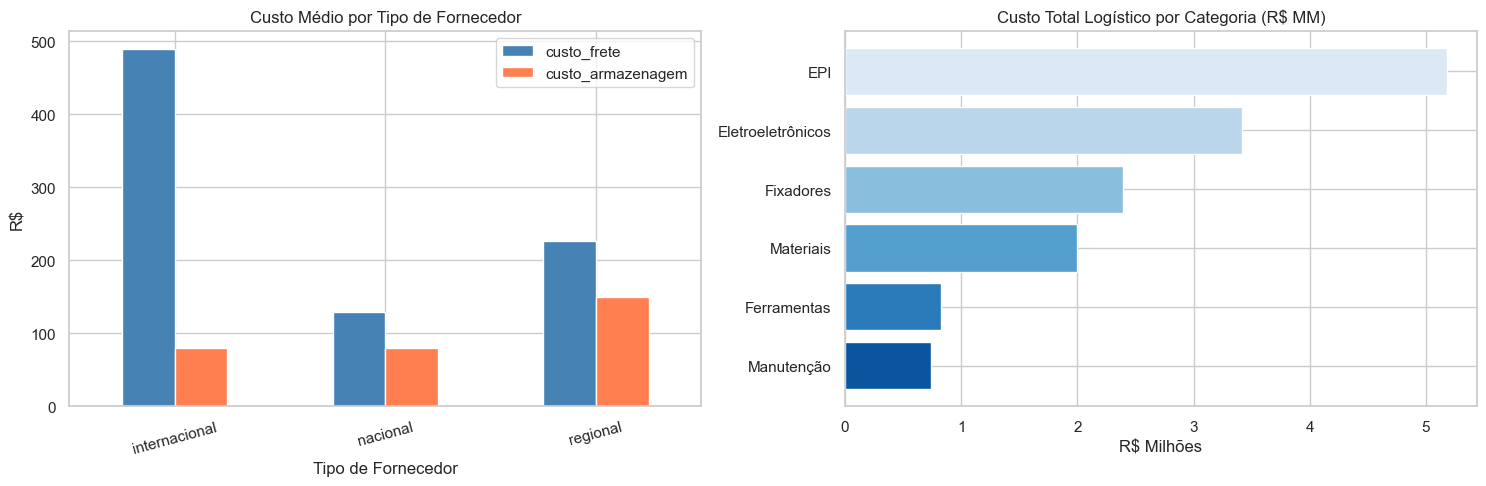

In [14]:
df['custo_total_logistico'] = df['custo_frete'] + df['custo_armazenagem']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Custo médio de frete por tipo de fornecedor
custo_tipo = df.groupby('tipo_fornecedor')[['custo_frete', 'custo_armazenagem']].mean()
custo_tipo.plot(kind='bar', ax=axes[0], color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('Custo Médio por Tipo de Fornecedor')
axes[0].set_ylabel('R$')
axes[0].set_xlabel('Tipo de Fornecedor')
axes[0].tick_params(axis='x', rotation=15)

# Custo total logístico por categoria
custo_cat = df.groupby('categoria')['custo_total_logistico'].sum().sort_values(ascending=True)
axes[1].barh(custo_cat.index, custo_cat.values / 1e6, color=sns.color_palette('Blues_r', len(custo_cat)))
axes[1].set_title('Custo Total Logístico por Categoria (R$ MM)')
axes[1].set_xlabel('R$ Milhões')

plt.tight_layout()
plt.show()

## Análise de Custos Logísticos

---

### Gráfico 1 — Custo Médio por Tipo de Fornecedor (R$)

| Tipo de Fornecedor | Custo Frete (aprox.) | Custo Armazenagem (aprox.) | Relação Frete/Armaz. |
|--------------------|----------------------|----------------------------|----------------------|
| Internacional      | ~R$ 490              | ~R$ 80                     | ~6,1x                |
| Nacional           | ~R$ 130              | ~R$ 80                     | ~1,6x                |
| Regional           | ~R$ 230              | ~R$ 150                    | ~1,5x                |

**Observações:**
- O **frete internacional** é o maior custo unitário da análise — quase **4x o frete nacional**
  e **2x o regional**, confirmando o impacto financeiro dos fornecedores asiáticos
  identificado nas análises de atraso.
- O **custo de armazenagem** se mantém similar entre internacional e nacional (~R$ 80),
  mas é significativamente maior no **regional (~R$ 150)** — possivelmente por
  maior volume de lotes intermediários ou estrutura de estoque descentralizada.
- Fornecedores **regionais** apresentam o pior custo de armazenagem,
  superando até o internacional nesse quesito.

---

### Gráfico 2 — Custo Total Logístico por Categoria (R$ Milhões)

| Categoria         | Custo Total (aprox.) |
|-------------------|----------------------|
| EPI               | ~R$ 5,1 MM           |
| Eletroeletrônicos | ~R$ 3,4 MM           |
| Fixadores         | ~R$ 2,4 MM           |
| Materiais         | ~R$ 2,0 MM           |
| Ferramentas       | ~R$ 0,9 MM           |
| Manutenção        | ~R$ 0,8 MM           |

**Observações:**
- **EPI domina os custos logísticos totais** (~R$ 5,1 MM), representando mais
  do que o dobro de Fixadores e mais de 6x Ferramentas/Manutenção.
- A categoria **Eletroeletrônicos** ocupa o segundo lugar em custo (~R$ 3,4 MM),
  consistente com o crescimento de demanda no 2º semestre observado anteriormente.
- **Ferramentas e Manutenção** apresentam os menores custos logísticos totais,
  alinhado com seus baixos volumes de demanda.
- A escala de azul (mais claro = maior custo) reforça visualmente a concentração
  de custo nas categorias superiores.

---

### Conclusões Combinadas

- **EPI concentra o maior custo logístico total E a maior taxa de ruptura** —
  é a categoria de maior risco financeiro e operacional do portfólio.
- O **frete internacional** é o principal driver de custo unitário;
  estratégias de **nearshoring ou substituição por fornecedores nacionais**
  poderiam reduzir significativamente o custo de frete (de ~R$490 para ~R$130).
- O **custo de armazenagem regional elevado** merece investigação —
  pode indicar ineficiência de gestão de lotes ou localização dos centros de distribuição.
- Recomenda-se análise de **TCO (Custo Total de Propriedade)** por fornecedor,
  combinando frete + armazenagem + impacto dos atrasos para decisões de sourcing.

## Matriz de Correlação

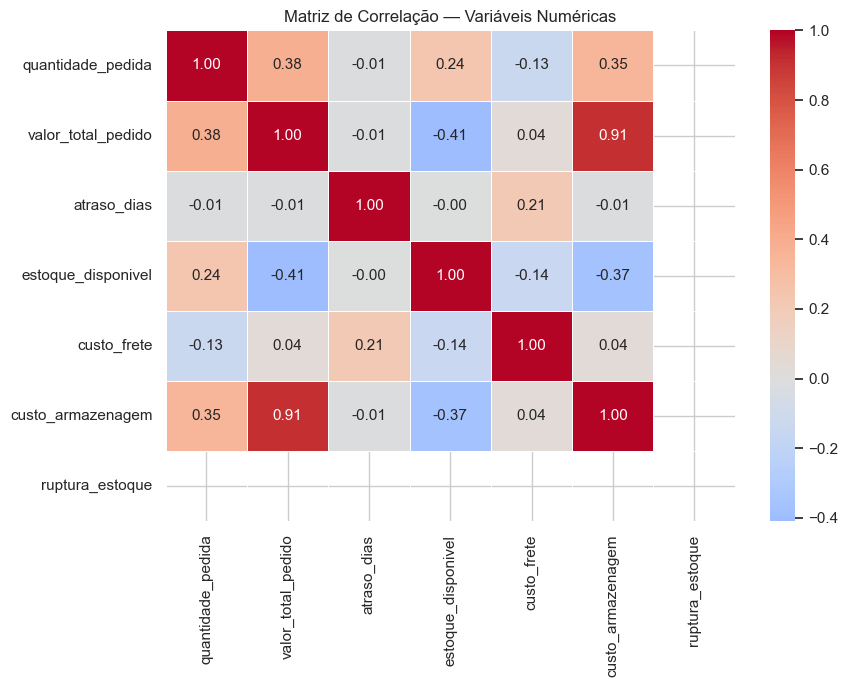

In [15]:
# Correlação entre variáveis numéricas
cols_corr = ['quantidade_pedida', 'valor_total_pedido', 'atraso_dias',
             'estoque_disponivel', 'custo_frete', 'custo_armazenagem',
             'ruptura_estoque']
corr = df[cols_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de Correlação — Variáveis Numéricas')
plt.tight_layout()
plt.show()

## Matriz de Correlação — Variáveis Numéricas

---

### Correlações Relevantes

#### Fortes (|r| > 0,7) — Vermelho escuro
| Par de Variáveis                          | Correlação | Interpretação                                                                 |
|-------------------------------------------|------------|-------------------------------------------------------------------------------|
| `valor_total_pedido` × `custo_armazenagem`| **+0.91**  | Pedidos de maior valor geram custos de armazenagem proporcionalmente maiores  |

#### Moderadas (0,3 < |r| < 0,7) — Vermelho/Azul médio
| Par de Variáveis                            | Correlação | Interpretação                                                              |
|---------------------------------------------|------------|----------------------------------------------------------------------------|
| `quantidade_pedida` × `valor_total_pedido`  | **+0.38**  | Mais itens pedidos tendem a gerar maior valor total (relação esperada)     |
| `quantidade_pedida` × `custo_armazenagem`   | **+0.35**  | Maiores volumes aumentam custos de armazenagem                             |
| `quantidade_pedida` × `estoque_disponivel`  | **+0.24**  | Leve tendência: mais pedidos onde há mais estoque disponível               |
| `valor_total_pedido` × `estoque_disponivel` | **-0.41**  | Pedidos de alto valor estão associados a menor estoque disponível          |
| `estoque_disponivel` × `custo_armazenagem`  | **-0.37**  | Maior estoque disponível está ligado a menor custo de armazenagem          |

#### Fracas ou Nulas (|r| < 0,25) — Cinza/Neutro
| Par de Variáveis                        | Correlação | Interpretação                                                                      |
|-----------------------------------------|------------|------------------------------------------------------------------------------------|
| `atraso_dias` × qualquer outra variável | ~0.00      | Atraso **não tem relação linear** com volume, valor ou estoque                     |
| `custo_frete` × `atraso_dias`           | **+0.21**  | Leve associação: fretes mais caros (internacionais) tendem a atrasar ligeiramente mais |
| `custo_frete` × `quantidade_pedida`     | **-0.13**  | Pedidos maiores tendem a ter frete levemente menor (possível economia de escala)   |

---

### Conclusões

- **Relação dominante:** `valor_total_pedido` e `custo_armazenagem` (r = 0,91) —
  o custo de armazenar é quase inteiramente explicado pelo valor financeiro do pedido,
  não pelo volume físico.
- **Atraso é independente** das demais variáveis numéricas — suas causas são
  qualitativas (tipo de fornecedor, rota, categoria), não quantitativas.
- **Estoque disponível** tem relação inversa com valor do pedido (-0,41) —
  itens de maior valor tendem a ter menor estoque disponível, aumentando
  o risco de ruptura para produtos de alto custo unitário.
- A **ruptura de estoque** não apresenta correlação mensurável com as variáveis
  numéricas contínuas — reforça que é um evento binário influenciado por fatores
  categóricos (giro, sazonalidade, categoria).

## 8. Análise Geográfica — Estados com Maior Volume

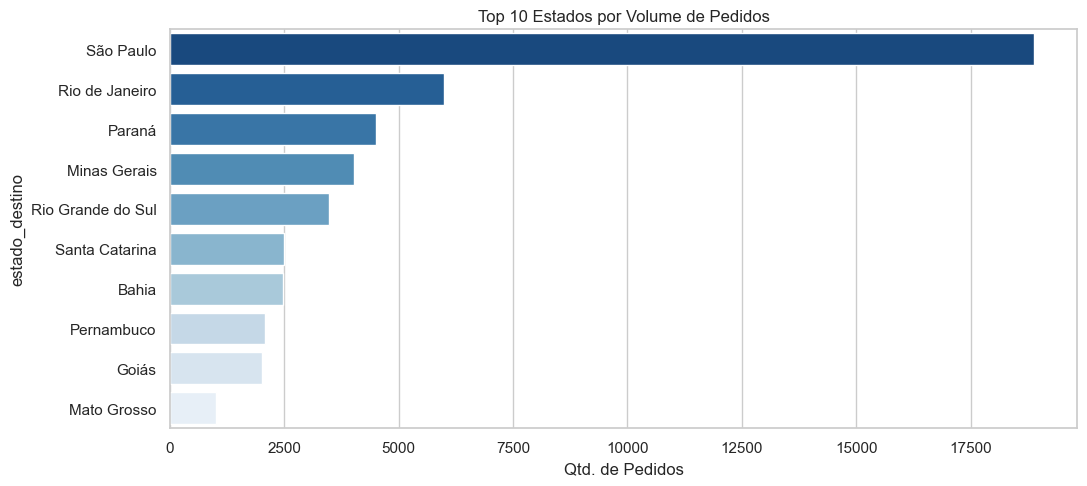

In [16]:
# Top 10 estados por volume de pedidos
top_estados = df['estado_destino'].value_counts().head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top_estados.values, y=top_estados.index, palette='Blues_r')
plt.title('Top 10 Estados por Volume de Pedidos')
plt.xlabel('Qtd. de Pedidos')
plt.tight_layout()
plt.show()

## 9. Resumo dos Principais Insights

| # | Insight | Impacto |
|---|---|---|
| 1 | Fornecedores internacionais concentram a maior parte dos atrasos | Alto |
| 2 | EPIs e Fixadores apresentam as maiores taxas de ruptura | Alto | 
| 3 | Demanda de EPI tem pico em Mar/Abr e Set/Out (auditoria CIPA) | Médio |
| 4 | Sudeste concentra ~60% dos pedidos (SP + MG + RJ) | Informativo |
| 5 | Produtos de giro baixo têm taxa de ruptura desproporcional | Médio |

> **Próxima etapa:** Limpeza e criação de features derivadas para modelagem.